# 08 · The decision rule: bid prices

The cancellation model says *how much* of a room a booking will use. The policy decides *who*
gets the rooms. For every request, on every night of the stay:

1. **Expected shows.** Each accepted booking counts `q = 1 − p_cancel` rooms. Overbooking comes
   from this alone: 130 bookings that each show up 79% of the time are 103 expected guests.
2. **Bid price.** The nightly rate of the *marginal guest we still expect to seat* on that night
   if we keep the room free. It is 0 when the night will not fill anyway, infinite when it is
   already full in expectation, and in between it rises as the night fills.
3. **Accept** when the request's nightly rate ≥ the average bid price of its nights **and** its
   expected shows fit the free rooms on every night.

Why compare the plain *rate* with the bid price, and not `q × rate`? A booking that shows up with
probability `q` earns `q × rate` per night and consumes `q` expected rooms, each worth the bid
price: `q × rate ≥ q × bid` ⇔ `rate ≥ bid`. The probability decides how much capacity is used; the
price decides who gets it.

In [1]:
import json
import sys
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.simulator import load_train, build_holdout, evaluate_local, score, ROOMS
from src.baselines import LoadLimit, ExpectedShows, oracle_accept
from src.policy import BidPricePolicy, LEAD_EDGES, _lead_bucket
from src.stream_model import StreamCancelModel
from src import plotting as P

P.setup()
pd.set_option("display.width", 180)
R = Path("..") / "experiments" / "results"
HOTELS = list(ROOMS)
df = load_train()

## 1 · Inside the forecast: a live example

A policy goes live on 1 July 2016, with a logistic-regression cancellation model trained on the
arrivals before that day (the forecast mechanics do not depend on which model is used). We replay
the requests up to 20 July and then look at one night: **Downtown, 15 September**.

In [2]:
ho = build_holdout(df, start="2016-07-01")
model = StreamCancelModel("lr").fit(ho.history, as_of=ho.days[0])
model.start_session(ho.commitments)
pol = BidPricePolicy(ho.commitments.copy(), {h: c.copy() for h, c in ho.capacity.items()}, history=ho.history, model=model)
TODAY = pd.Timestamp("2016-07-20")
for b in ho.requests[ho.requests.booking_date < TODAY].to_dict("records"):
    pol.decide(b)

H, NIGHT = "Downtown Hotel", pd.Timestamp("2016-09-15")
d, t = (NIGHT - pol.start).days, (TODAY - pol.start).days
fc = pol.forecast
free = pol.load.cap[H][d] - pol.load.E[H][d]
c = fc.components(H, d, t, free)
pd.Series({"capacity": pol.load.cap[H][d], "expected shows already accepted": pol.load.E[H][d],
           "free rooms (in expectation)": free, "days ahead (L)": c["lead"],
           "share of demand usually booked by now F(L)": c["F"], "growth factor g": c["growth"],
           "same night last year mu": fc.mu[H][d], "total demand T = g x mu": c["T"],
           "demand still to come N = T x (1 - F)": c["N"], "price level of the night P": c["P"],
           "bid price": c["bid"]}).round(2).to_frame("value")

,value
capacity,124.00
expected shows already accepted,57.56
free rooms (in expectation),66.44
days ahead (L),57.00
share of demand usually booked by now F(L),0.45
growth factor g,1.74
same night last year mu,183.04
total demand T = g x mu,318.18
demand still to come N = T x (1 - F),174.51
price level of the night P,130.46


On 20 July the policy has already accepted 57.6 expected guests for Downtown on 15 September, so
**66 rooms are free** in expectation. Last year the same weekday had 183 expected guests; demand
this year is running 74% ahead of last year's pace (growth factor, capped at 1.8), so the forecast
is **318 expected guests in total**. At 57 days out, only 45% of a night's demand is usually on
the books, so **175 guests are still to come**.

We can seat 66 of those 175: the best-paying 38%. The marginal guest is therefore at the **62nd
percentile** of the rates that late bookers pay, which from the training history is 1.11 × the
price level of the night (€130): **bid price ≈ €145**. A request for that night at €160 is
accepted; one at €120 is turned away, because a better-paying guest is still expected to want
the room.

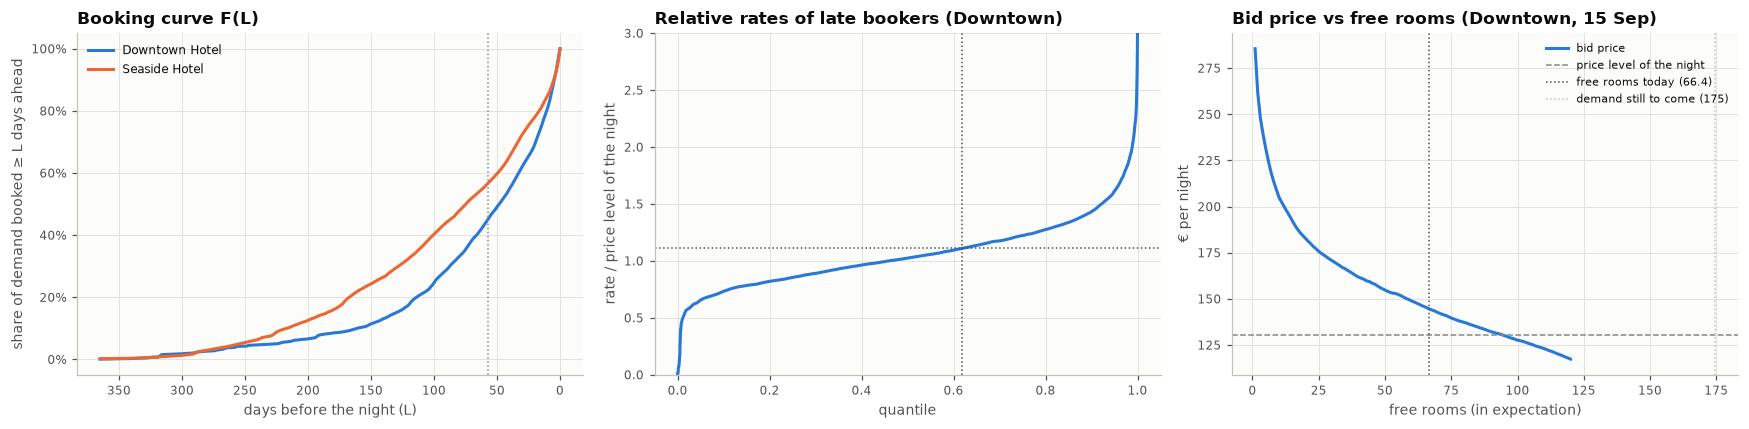

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
L = np.arange(0, 366)
for h in HOTELS:
    axes[0].plot(L, fc.F[h][L], color=P.HOTEL_COLORS[h], label=h)
axes[0].axvline(c["lead"], color=P.MUTED, ls=":", lw=1)
axes[0].invert_xaxis(); axes[0].yaxis.set_major_formatter(P.PCT)
axes[0].set(title="Booking curve F(L)", xlabel="days before the night (L)", ylabel="share of demand booked ≥ L days ahead")
axes[0].legend()

j = _lead_bucket(c["lead"])
rq, rc = fc.rel_q[H][j], fc.rel_cdf[H][j]
axes[1].plot(rc, rq, color=P.HOTEL_COLORS[H])
if c["quantile"] is not None:
    axes[1].axvline(c["quantile"], color=P.INK_2, ls=":", lw=1)
    axes[1].axhline(c["bid"] / c["P"], color=P.INK_2, ls=":", lw=1)
axes[1].set(title=f"Relative rates of late bookers ({H.split()[0]})",
            xlabel="quantile", ylabel="rate / price level of the night", ylim=(0, 3))

frees = np.arange(1, 121)
bids = [fc.components(H, d, t, f)["bid"] for f in frees]
axes[2].plot(frees, bids, color=P.HOTEL_COLORS[H], label="bid price")
axes[2].axhline(c["P"], color=P.MUTED, ls="--", lw=1, label="price level of the night")
axes[2].axvline(free, color=P.INK_2, ls=":", lw=1, label=f"free rooms today ({free:.1f})")
axes[2].axvline(c["N"], color=P.LIGHT, ls=":", lw=1, label=f"demand still to come ({c['N']:.0f})")
axes[2].set(title=f"Bid price vs free rooms ({H.split()[0]}, {NIGHT:%d %b})",
            xlabel="free rooms (in expectation)", ylabel="€ per night")
axes[2].legend(fontsize=7)
P.save(fig, "bid_price_mechanics")
plt.tight_layout(); plt.show()

**Left:** the booking curves. Seaside books earlier than Downtown; 57 days out, Downtown has 45%
of a night's demand on the books. **Centre:** the distribution of relative rates among guests who
book late; the dotted lines mark the 62nd percentile used in the example. **Right:** the bid
price as a function of free rooms for the same night and day. With few free rooms only the very
best late payers will get them, so the bid price climbs steeply (above €250 with five rooms
left); with more free rooms than demand still to come it would drop to zero. As the hotel fills
up during the booking season, the price automatically rises.

## 2 · A half-year of decisions

The full trace of the shipped recipe (stack of LR + LightGBM + CatBoost, shift 0) on the second half of 2016, with the
model trained only on arrivals before 1 July (`experiments/05_decision_trace.py`).

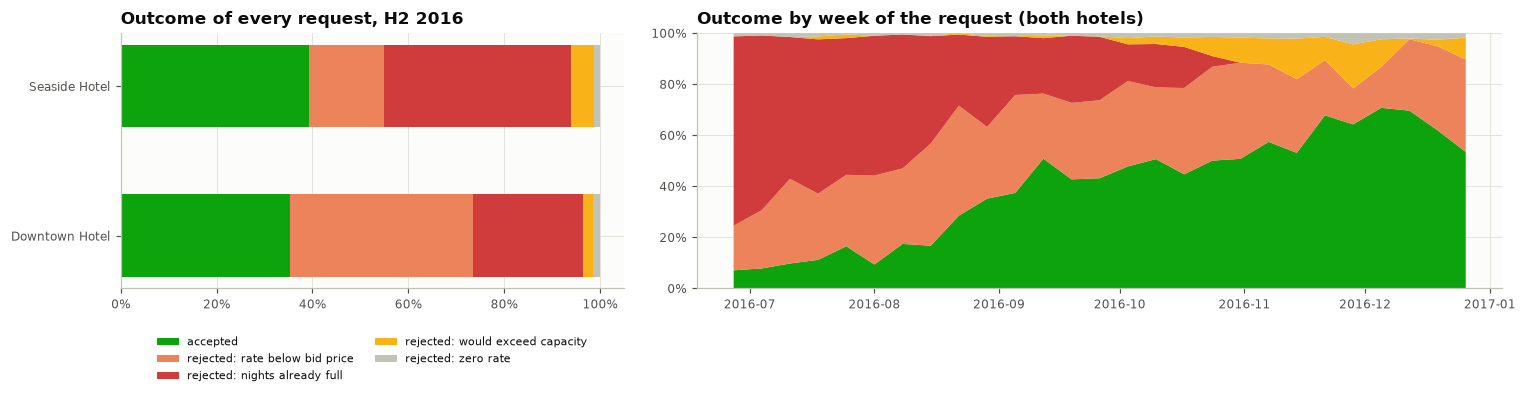

outcome,accepted,price,full,capacity,invalid
hotel,,,,,
Downtown Hotel,0.353,0.382,0.229,0.022,0.014
Seaside Hotel,0.393,0.156,0.391,0.048,0.012


In [4]:
tr = pd.read_csv(R / "05_decisions_H2.csv", parse_dates=["booking_date", "arrival_date"])
mix = tr.groupby(["hotel", "outcome"]).size().unstack().fillna(0)
mix = mix.div(mix.sum(axis=1), axis=0)[["accepted", "price", "full", "capacity", "invalid"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
left = np.zeros(len(mix))
for o in mix.columns:
    axes[0].barh(mix.index, mix[o], left=left, color=P.OUTCOME_COLORS[o], label=P.OUTCOME_LABELS[o], height=.55)
    left += mix[o].to_numpy()
axes[0].xaxis.set_major_formatter(P.PCT); axes[0].set_title("Outcome of every request, H2 2016")
axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(.5, -.15), ncol=2)
m = tr.groupby([tr.booking_date.dt.to_period("W").dt.start_time, "outcome"]).size().unstack().fillna(0)
m = m.div(m.sum(axis=1), axis=0)
axes[1].stackplot(m.index, *[m.get(o, 0) for o in mix.columns], colors=[P.OUTCOME_COLORS[o] for o in mix.columns])
axes[1].yaxis.set_major_formatter(P.PCT); axes[1].set(title="Outcome by week of the request (both hotels)", ylim=(0, 1))
plt.tight_layout(); plt.show()
mix.round(3)

Over July–December only **35–39% of the requests are accepted**. At Downtown the most frequent
reason for rejection is price (38% of requests: a better-paying guest is expected); at Seaside it
is that the nights are already full in expectation (39%), because the commitments inherited on
1 July already exceed capacity on most summer nights. The capacity check alone rarely decides
(2–5%): when a night is close to full, the bid price is usually already above the rate.

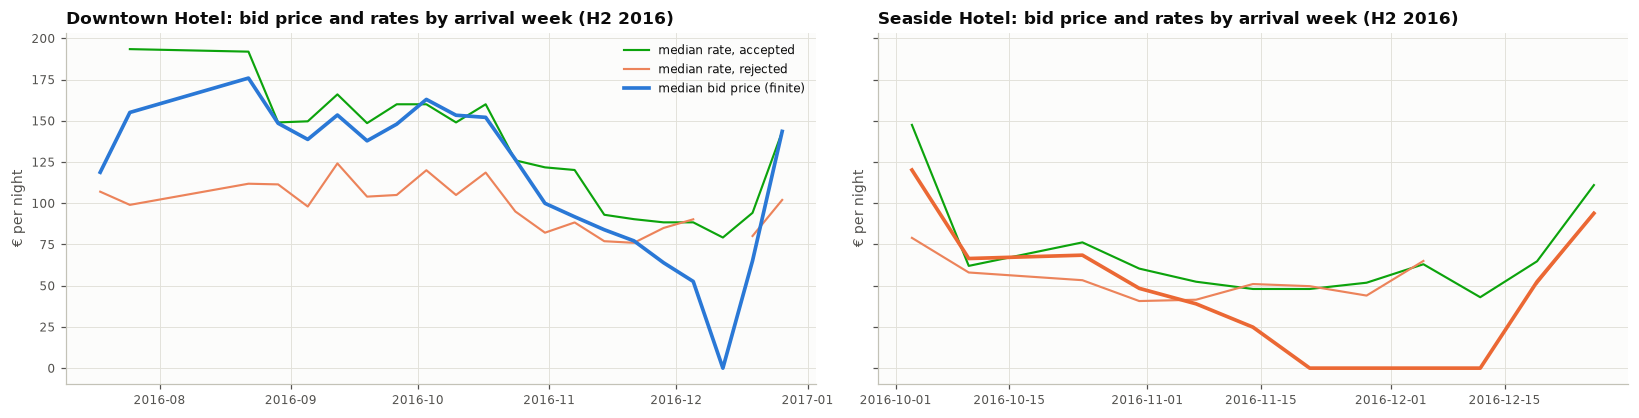

In [5]:
fin = tr[np.isfinite(tr.bid) & (tr.outcome != "invalid")]
wk = fin.groupby(["hotel", fin.arrival_date.dt.to_period("W").dt.start_time]).agg(
    bid=("bid", "median"), rate_acc=("rate", lambda s: s[fin.loc[s.index, "accepted"]].median()),
    rate_rej=("rate", lambda s: s[~fin.loc[s.index, "accepted"]].median()), n=("bid", "size"))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.9), sharey=True)
for ax, h in zip(axes, HOTELS):
    x = wk.loc[h]
    x = x[(x.n >= 20) & (x.index < "2017-01-01")]
    ax.plot(x.index, x.rate_acc, color=P.GOOD, lw=1.4, label="median rate, accepted")
    ax.plot(x.index, x.rate_rej, color=P.SERIOUS, lw=1.4, label="median rate, rejected")
    ax.plot(x.index, x.bid, color=P.HOTEL_COLORS[h], lw=2.4, label="median bid price (finite)")
    ax.set(title=f"{h}: bid price and rates by arrival week (H2 2016)", ylabel="€ per night")
axes[0].legend()
P.save(fig, "bid_price_over_time")
plt.tight_layout(); plt.show()

The bid price **follows the season**: at Downtown it is around €150 in September–October and falls
towards €50–100 in November–December, when demand no longer fills the hotel; at Seaside finite bid
prices appear only from October (summer nights are already full) and drop to zero in the quiet
weeks of November–December, when everything with a positive rate is accepted. Accepted requests
sit just above the bid line, rejected ones below it.

## 3 · Results on the 2016 replay

Baselines are recomputed here on the three windows; model rows come from
`experiments/03_finalists.py` (mean of three within-day orders).

In [6]:
WINDOWS = {"H1": dict(start="2016-01-01", end="2016-06-30"), "H2": dict(start="2016-07-01"), "FY": dict(year=2016)}
rows = {}
for w, kw in WINDOWS.items():
    hw = build_holdout(df, **kw)
    rows[("No overbooking", w)] = evaluate_local(LoadLimit, hw).net.sum()
    rows[("Overbooking at the average rate", w)] = evaluate_local(partial(ExpectedShows, history=hw.history), hw).net.sum()
    rows[("Oracle (knows who shows up)", w)] = score(hw, oracle_accept(hw)).net.sum()
base = pd.Series(rows).unstack() / 1e6
fin3 = pd.read_csv(R / "03_finalists.csv")
f0 = fin3[fin3["shift"] == 0].groupby(["config", "window"]).net_M.mean().unstack()
res = pd.concat([base.loc[["No overbooking", "Overbooking at the average rate"]],
                 f0.loc[["lr", "lgb", "stack_lr_lgb_cb"]].rename(index={"lr": "Bid price + logistic regression",
                                                                       "lgb": "Bid price + LightGBM",
                                                                       "stack_lr_lgb_cb": "Bid price + stack (shipped)"}),
                 base.loc[["Oracle (knows who shows up)"]]])[["H1", "H2", "FY"]]
res["FY vs average-rate baseline"] = res.FY / res.loc["Overbooking at the average rate", "FY"] - 1
res["share of the gap to the oracle closed (FY)"] = (res.FY - res.loc["Overbooking at the average rate", "FY"]) / \
    (res.loc["Oracle (knows who shows up)", "FY"] - res.loc["Overbooking at the average rate", "FY"])
res.round(3)

,H1,H2,FY,FY vs average-rate baseline,share of the gap to the oracle closed (FY)
No overbooking,1.638,1.101,3.790,-0.279,-0.586
Overbooking at the average rate,2.246,1.420,5.257,0.000,0.000
Bid price + logistic regression,2.693,1.711,6.492,0.235,0.493
Bid price + LightGBM,2.364,1.730,5.926,0.127,0.267
Bid price + stack (shipped),2.683,1.694,6.328,0.204,0.428
Oracle (knows who shows up),3.068,1.933,7.761,0.476,1.000


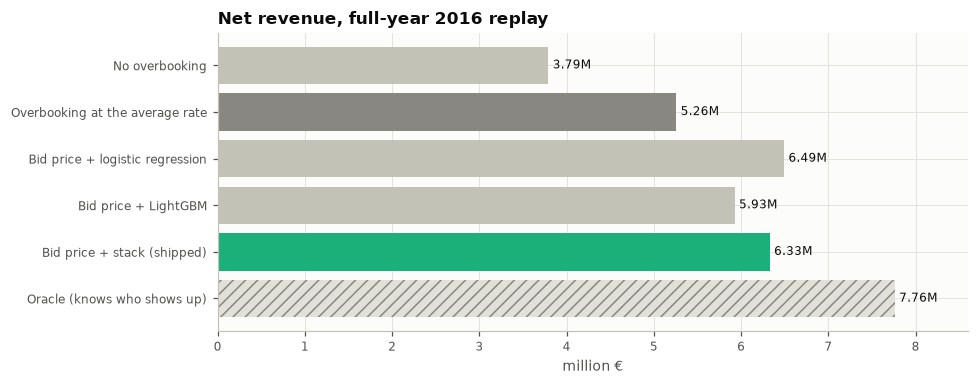

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
v = res.FY
colors = [P.LIGHT, P.MUTED, P.LIGHT, P.LIGHT, P.OURS, P.GRID]
bars = ax.barh(v.index[::-1], v[::-1], color=colors[::-1])
bars[0].set_hatch("///"); bars[0].set_edgecolor(P.MUTED)
for i, x in enumerate(v[::-1]):
    ax.text(x + .05, i, f"{x:.2f}M", va="center", fontsize=8)
ax.set(title="Net revenue, full-year 2016 replay", xlabel="million €", xlim=(0, 8.6))
P.save(fig, "results")
plt.tight_layout(); plt.show()

**The shipped system makes 6.33M on the 2016 replay, +20% over classic overbooking (5.26M), and
closes 43% of the gap to an oracle that knows in advance who will show up.** The logistic
regression variant does slightly better on the full year (6.49M, 49% of the gap) and the LightGBM
variant clearly worse (5.93M); on H1+H2 the stack and logistic regression differ by 0.03M, within
the noise of a single validation year (notebook 07).

In the second half of the year the commitments inherited on 1 July already exceed capacity on
many summer nights: every policy, including the oracle, pays for those walks, which is why H2
revenue is much lower than H1.

## 4 · Where does the gain come from?

Two ingredients: a per-booking probability, and the bid price. To separate them, the same
logistic-regression model is used inside the *first come, first served* rule (accept while the
expected shows fit, no price test).

In [8]:
class ExpectedShowsModel(LoadLimit):
    """First come, first served on expected shows, with a per-booking probability from `model`."""

    def __init__(self, commitments, capacity, model):
        self.model = model
        model.start_session(commitments)
        super().__init__(commitments, capacity)

    def weight(self, b):
        return 1.0 - self.model.predict_one(b)        # cached by booking_id, so safe to call twice


grid = pd.read_csv(R / "02_recipe_grid.csv")
lr_bid = grid[(grid.config == "lr") & (grid["shift"] == 0) & (grid.seed == 0)].set_index("window").net_M
steps = []
for w in ("H1", "H2"):
    hw = build_holdout(df, **WINDOWS[w])
    m = StreamCancelModel("lr").fit(hw.history, as_of=hw.days[0])
    steps.append({"window": w,
                  "average rate per hotel (FCFS)": base.loc["Overbooking at the average rate", w],
                  "+ per-booking probability (FCFS)": evaluate_local(partial(ExpectedShowsModel, model=m), hw).net.sum() / 1e6,
                  "+ bid price": lr_bid[w]})
steps = pd.DataFrame(steps).set_index("window")
steps.loc["H1+H2"] = steps.sum()
steps.round(3)

,average rate per hotel (FCFS),+ per-booking probability (FCFS),+ bid price
window,,,
H1,2.246,2.338,2.692
H2,1.420,1.516,1.714
H1+H2,3.666,3.854,4.406


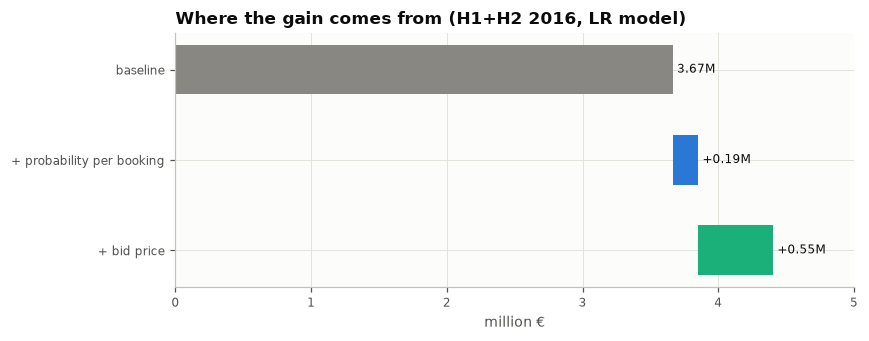

In [9]:
s = steps.loc["H1+H2"]
fig, ax = plt.subplots(figsize=(8, 3.2))
gain1, gain2 = s.iloc[1] - s.iloc[0], s.iloc[2] - s.iloc[1]
ax.barh(["baseline", "+ probability per booking", "+ bid price"], [s.iloc[0], gain1, gain2],
        left=[0, s.iloc[0], s.iloc[1]], color=[P.MUTED, P.BLUE, P.OURS], height=.55)
for i, (x, g) in enumerate([(s.iloc[0], s.iloc[0]), (s.iloc[1], gain1), (s.iloc[2], gain2)]):
    ax.text(x + .03, i, f"{'+' if i else ''}{g:.2f}M", va="center", fontsize=8)
ax.invert_yaxis(); ax.set(title="Where the gain comes from (H1+H2 2016, LR model)", xlabel="million €", xlim=(0, 5))
P.save(fig, "gain_decomposition")
plt.tight_layout(); plt.show()

Starting from classic overbooking (3.67M on H1+H2), **replacing the hotel-wide cancellation rate
with a per-booking probability adds 0.19M**; **adding the bid price adds another 0.55M**. The price
test is the bigger lever: the probability tells how many bookings fit, but only the bid price
keeps the rooms for the guests who pay more and show up more often.

## 5 · A year of nights

Full-year replay of the shipped recipe (model trained before 1 January): rooms occupied by seated
guests and walked arrivals, per night.

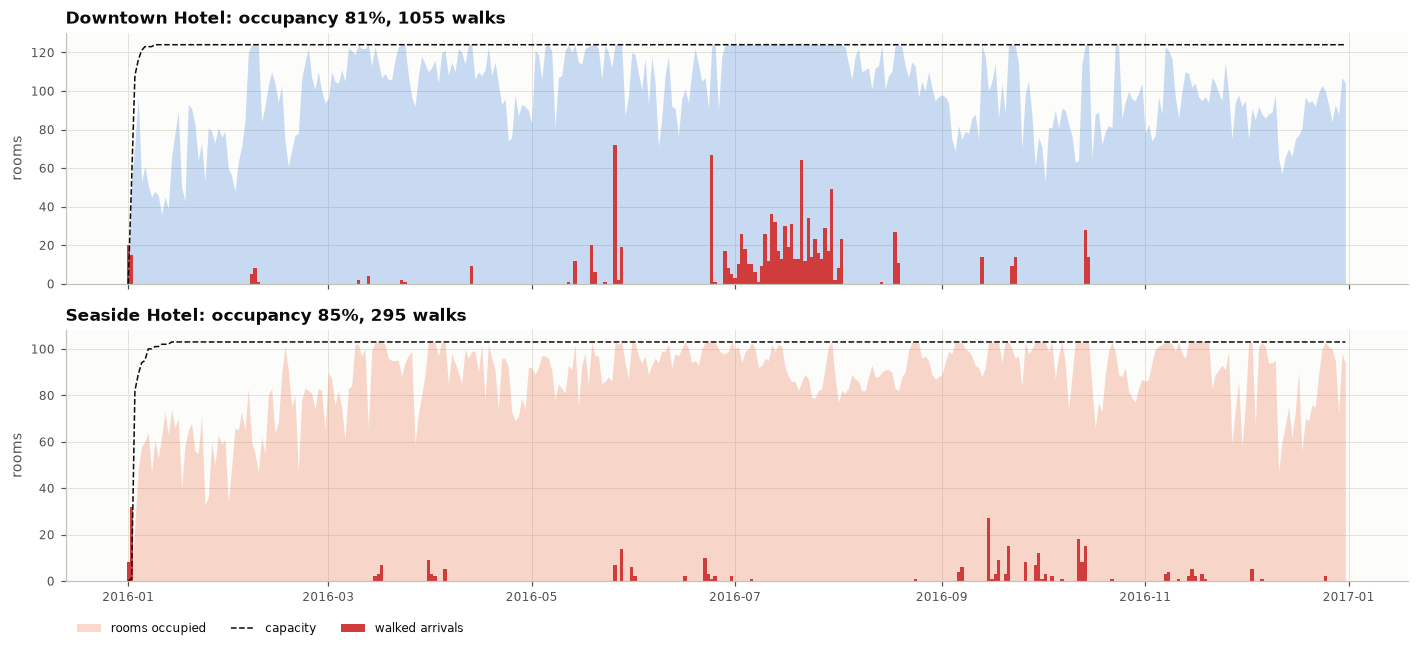

,full year 2016
net,6328439.625
revenue,6996639.700
penalty,668200.075
walk,1350.000
accepted,23876.000
requests,44247.000
occupancy,0.829
revenue_per_occupied_room_night,102.154


In [10]:
nights = pd.read_csv(R / "05_nights_FY.csv", parse_dates=["night"])
summ = json.load(open(R / "05_summary.json"))["FY"]
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, h in zip(axes, HOTELS):
    x = nights[nights.hotel == h]
    ax.fill_between(x.night, x.seated, color=P.HOTEL_COLORS[h], alpha=.25, lw=0, label="rooms occupied")
    ax.plot(x.night, x.capacity, color=P.INK, lw=1, ls="--", label="capacity")
    ax.bar(x.night, x.walked_arrivals, color=P.CRITICAL, width=1, label="walked arrivals")
    ax.set(title=f"{h}: occupancy {x.seated.sum() / x.capacity.sum():.0%}, {int(x.walked_arrivals.sum())} walks",
           ylabel="rooms")
axes[1].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3)
P.save(fig, "year_of_nights")
plt.tight_layout(); plt.show()
pd.Series({k: summ[k] for k in ["net", "revenue", "penalty", "walk", "accepted", "requests", "occupancy",
                                "revenue_per_occupied_room_night"]}).round(3).to_frame("full year 2016")

Over the full year the hotels run at **81% (Downtown) and 85% (Seaside) occupancy** of the rooms
available, at **€102 per occupied room-night**. Walks are concentrated in a few weeks: the first
days of January (guests of December still in house), May–July at Downtown (839 of its 1,055 walks,
608 in July alone) and September–October at Seaside. Those are the weeks in which more accepted
guests showed up than the model expected: summer 2016 cancelled less than the history used for
training. Outside them the policy runs close to full without walking guests.

## 6 · Policy variants that did not make it

In [11]:
pa = pd.read_csv(R / "04_policy_ablation.csv")
p = pa.groupby(["config", "window"]).net_M.mean().unstack()
p["H1+H2"] = p.H1 + p.H2
p["Δ vs base (H1+H2)"] = p["H1+H2"] - p.loc["base", "H1+H2"]
p.sort_values("H1+H2", ascending=False).round(3)

window,FY,H1,H2,H1+H2,Δ vs base (H1+H2)
config,,,,,
bid1.1,6.499,2.701,1.720,4.422,0.022
base,6.493,2.689,1.711,4.400,0.000
displace5,6.481,2.695,1.704,4.399,-0.001
z0.5,6.496,2.687,1.706,4.392,-0.008
displace3.5,6.441,2.662,1.672,4.335,-0.065
bid0.9,6.340,2.622,1.675,4.297,-0.103
bid0.9+displace3.5,6.209,2.555,1.615,4.170,-0.230
displace2.5,6.372,2.623,1.545,4.168,-0.231


Variants tested with the LR model, three within-day orders, H1+H2 and full year:

| Variant | Δ H1+H2 | Verdict |
|---|---|---|
| Bid price × 1.1 | +0.022M | inside the noise; not adopted (a parameter tuned on 2016) |
| Safety margin z = 0.5 standard deviations | −0.008M | no gain: the walk penalty is already priced by the expected-show count |
| Price the walk instead of refusing a full night (k = 3.5 × P(full) × cheapest rate) | −0.065M | worse; k = 2.5 much worse (−0.23M) |
| Bid price × 0.9 | −0.103M | worse: being less selective costs money |

The simple rule (rate ≥ bid price, expected shows ≤ capacity, no extra margin) is also the best
one found.

## Limits

* **One out-of-sample year.** The demand forecast relies on last year's pattern and on the growth
  factor (bounded to [0.6, 1.8]); a very different year would break both.
* **The model is frozen for a year** and, at the July cut, under-predicts cancellations by about
  4 points.
* **Selection bias.** The training data contains only bookings that were accepted in the past;
  demand that was turned away is invisible to the forecast.
* **Group variance is not in the capacity check.** Blocks are recognised by the model, but the
  capacity test uses expected shows, not their variance (a margin was tested and did not help).